# Persistent Activity and Anomaly Detection: Baseline Reproduction

**Target Project:** Persistent Activity and Anomaly Detection  
**Upstream Repository:** [https://github.com/bravo2024/HAR](https://github.com/bravo2024/HAR)  
**Objective:** Reproduce the complete baseline pipeline for the UCI Human Activity Recognition (HAR) dataset using Google Colab with GPU acceleration and persistent storage on Google Drive.

### Baseline Models Under Evaluation:
1. **Random Forest** — 561 engineered features (expert time/frequency domain domain features)
2. **LSTM** — 2-layer bidirectional LSTM on raw 9-channel × 128-timestep inertial sequences
3. **GRU** — 2-layer bidirectional GRU on raw 9-channel × 128-timestep inertial sequences
4. **1D-CNN** — 3-block 1D convolutional network with global average pooling on raw sequences

### Methodological Note on Checkpoint Selection:
In the original `har.py` implementation, deep model checkpoints are saved based on peak test accuracy evaluated on the test set during training (`if test_acc > best_test_acc`). In standard machine learning practice, hyperparameter and checkpoint selection should ideally use an independent validation set to prevent test leakage. In this baseline reproduction phase, we preserve the original logic verbatim to accurately assess the published baseline.

## 1. Persistent Storage Setup (Google Drive)
Mount Google Drive and create a dedicated workspace folder `Persistent Activity and Anomaly Detection` so that trained model weights, evaluation metrics, and figures persist across Colab runtime disconnections.

In [ ]:
from google.colab import drive
import os
from pathlib import Path

# Mount Google Drive
drive.mount('/content/drive')

# Define persistent project workspace directory
PROJECT_DIR = Path('/content/drive/MyDrive/Persistent Activity and Anomaly Detection')
OUT_DIR = PROJECT_DIR / 'out'
LOG_DIR = PROJECT_DIR / 'logs'
FIGURES_DIR = PROJECT_DIR / 'figures'

for d in [PROJECT_DIR, OUT_DIR, LOG_DIR, FIGURES_DIR]:
    d.mkdir(parents=True, exist_ok=True)

print(f"Persistent project workspace initialized at: {PROJECT_DIR}")
print(f"Checkpoints and metrics will be saved to: {OUT_DIR}")

Mounted at /content/drive
Persistent project workspace initialized at: /content/drive/MyDrive/Persistent Activity and Anomaly Detection
Checkpoints and metrics will be saved to: /content/drive/MyDrive/Persistent Activity and Anomaly Detection/out


## 2. Environment Verification & Hardware Inspection
Verify Colab runtime hardware (detect GPU if allocated) and verify pre-installed PyTorch and scikit-learn libraries. We avoid reinstalling PyTorch or installing unneeded packages to preserve Colab's optimized CUDA setup.

In [ ]:
import torch
import numpy as np
import sklearn
import pandas as pd
import matplotlib

# Check hardware acceleration
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("=== Environment Verification ===")
print(f"Compute Device  : {device}")
if torch.cuda.is_available():
    print(f"GPU Model       : {torch.cuda.get_device_name(0)}")
    print(f"VRAM Available  : {torch.cuda.get_device_properties(0).total_memory / (1024**3):.2f} GB")
else:
    print("Note: Running on CPU runtime. GPU is recommended for faster deep model execution.")

print(f"PyTorch Version : {torch.__version__}")
print(f"CUDA Available  : {torch.cuda.is_available()}")
print(f"NumPy Version   : {np.__version__}")
print(f"Scikit-Learn    : {sklearn.__version__}")
print(f"Pandas Version  : {pd.__version__}")

=== Environment Verification ===
Compute Device  : cuda
GPU Model       : Tesla T4
VRAM Available  : 14.56 GB
PyTorch Version : 2.14.1+cu130
CUDA Available  : True
NumPy Version   : 2.4.6
Scikit-Learn    : 1.6.1
Pandas Version  : 2.2.3


## 3. Clone Repository & Prepare Dataset
Clone the official repository `bravo2024/HAR` into `/content/HAR`. The dataset is packaged inside `data/UCI HAR Dataset.zip` and will be extracted cleanly without modifying upstream git tracking.

In [ ]:
import sys
import zipfile
import shutil

REPO_DIR = Path('/content/HAR')
if not REPO_DIR.exists():
    !git clone https://github.com/bravo2024/HAR.git /content/HAR
else:
    print("Repository already cloned at /content/HAR")

# Add repository to Python search path
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))

# Extract UCI HAR dataset if not already extracted
DATA_DIR = REPO_DIR / 'data'
DATASET_ROOT = DATA_DIR / 'UCI HAR Dataset'

if not DATASET_ROOT.exists():
    zip_path = DATA_DIR / 'UCI HAR Dataset.zip'
    if zip_path.exists():
        print(f"Extracting {zip_path}...")
        with zipfile.ZipFile(zip_path, 'r') as zf:
            zf.extractall(DATA_DIR)
    else:
        import har
        DATASET_ROOT = har.download_and_extract(DATA_DIR)

print(f"Dataset ready at: {DATASET_ROOT}")

Cloning into '/content/HAR'...
remote: Enumerating objects: 53, done.
remote: Counting objects: 100% (3/3), done.
remote: Compressing objects: 100% (3/3), done.
remote: Total 53 (delta 0), reused 2 (delta 0), pack-reused 50 (from 1)
Receiving objects: 100% (53/53), 121.63 MiB | 19.77 MiB/s, done.
Resolving deltas: 100% (1/1), done.
Updating files: 100% (42/42), done.
Dataset ready at: /content/HAR/data/UCI HAR Dataset


## 4. Dataset Loading & Split Verification
Load both the 9-channel raw inertial sequences and the 561 hand-engineered features. Verify that the official subject-independent train/test split (21 subjects train, 9 subjects test) is strictly preserved.

In [ ]:
from har import load_raw_signals, load_engineered_features, ACTIVITIES, N_CLASSES, SEED, set_seed

# Set seed for full determinism
set_seed(SEED)

# Load raw 9-channel sequences for deep learning models
print("Loading raw inertial signals (9x128)...")
X_train_seq, y_train = load_raw_signals(DATASET_ROOT, 'train')
X_test_seq, y_test = load_raw_signals(DATASET_ROOT, 'test')

# Load 561 pre-engineered features for classical Random Forest
print("Loading 561 engineered features...")
X_train_eng, _ = load_engineered_features(DATASET_ROOT, 'train')
X_test_eng, _ = load_engineered_features(DATASET_ROOT, 'test')

print("\n=== Dataset Shape Verification ===")
print(f"Train Raw Sequences       : {X_train_seq.shape}  (Expected: (7352, 9, 128))")
print(f"Test Raw Sequences        : {X_test_seq.shape}   (Expected: (2947, 9, 128))")
print(f"Train Engineered Features : {X_train_eng.shape}  (Expected: (7352, 561))")
print(f"Test Engineered Features  : {X_test_eng.shape}   (Expected: (2947, 561))")
print(f"Target Class Distribution : {N_CLASSES} classes -> {ACTIVITIES}")

Loading raw inertial signals (9x128)...
Loading 561 engineered features...

=== Dataset Shape Verification ===
Train Raw Sequences       : (7352, 9, 128)  (Expected: (7352, 9, 128))
Test Raw Sequences        : (2947, 9, 128)   (Expected: (2947, 9, 128))
Train Engineered Features : (7352, 561)  (Expected: (7352, 561))
Test Engineered Features  : (2947, 561)   (Expected: (2947, 561))
Target Class Distribution : 6 classes -> ['walking', 'walking-upstairs', 'walking-downstairs', 'sitting', 'standing', 'laying']


## 5. Model Architectures & Device-Aware Training Loop
We instantiate the exact model architectures from the original `har.py`:
- `LSTMModel`: 2-layer biLSTM (hidden=128, dropout=0.3) -> temporal avg pooling -> Linear(256, 6)
- `GRUModel`: 2-layer biGRU (hidden=128, dropout=0.3) -> temporal avg pooling -> Linear(256, 6)
- `CNN1DModel`: 3-block 1D-CNN (conv 64 -> 128 -> 256) -> GAP -> Dropout(0.3) -> Linear(256, 6)

We provide a device-aware execution wrapper that moves tensors and models to GPU (`device`) if available, while maintaining 100% mathematical fidelity to `har.py` (AdamW, CosineAnnealingLR, seed 42, test-set checkpoint selection).

In [ ]:
import time
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from har import LSTMModel, GRUModel, CNN1DModel, HARSequenceDataset

MODEL_CLASSES = {
    'lstm': LSTMModel,
    'gru': GRUModel,
    'cnn1d': CNN1DModel,
}

def train_epoch_device(model, loader, optimizer, criterion, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for Xb, yb in loader:
        Xb, yb = Xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(Xb)
        loss = criterion(logits, yb)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * Xb.size(0)
        correct += (logits.argmax(1) == yb).sum().item()
        total += Xb.size(0)
    return total_loss / total

@torch.no_grad()
def eval_epoch_device(model, loader, criterion, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_labels = [], []
    for Xb, yb in loader:
        Xb_dev, yb_dev = Xb.to(device), yb.to(device)
        logits = model(Xb_dev)
        loss = criterion(logits, yb_dev)
        total_loss += loss.item() * Xb.size(0)
        preds = logits.argmax(1)
        correct += (preds == yb_dev).sum().item()
        total += Xb.size(0)
        all_preds.append(preds.cpu().numpy())
        all_labels.append(yb.numpy())
    acc = correct / total
    all_preds = np.concatenate(all_preds)
    all_labels = np.concatenate(all_labels)
    return total_loss / total, acc, all_preds, all_labels

def train_and_evaluate_deep_model(model_type, X_tr, y_tr, X_te, y_te, out_dir, epochs=15, lr=1e-3, batch_size=64, device=device):
    print(f"\n{'='*25} Training {model_type.upper()} on {device} ({epochs} epochs) {'='*25}")
    start_time = time.time()

    ds_train = HARSequenceDataset(X_tr, y_tr)
    ds_test = HARSequenceDataset(X_te, y_te)
    loader_train = torch.utils.data.DataLoader(ds_train, batch_size=batch_size, shuffle=True)
    loader_test = torch.utils.data.DataLoader(ds_test, batch_size=batch_size, shuffle=False)

    model = MODEL_CLASSES[model_type]().to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)

    best_test_acc = 0.0
    best_weights = None
    best_epoch = 0
    history = {'train_loss': [], 'test_loss': [], 'test_acc': []}

    for epoch in range(1, epochs + 1):
        train_loss = train_epoch_device(model, loader_train, optimizer, criterion, device)
        test_loss, test_acc, _, _ = eval_epoch_device(model, loader_test, criterion, device)
        scheduler.step()

        history['train_loss'].append(train_loss)
        history['test_loss'].append(test_loss)
        history['test_acc'].append(test_acc)

        if test_acc > best_test_acc:
            best_test_acc = test_acc
            best_epoch = epoch
            best_weights = {k: v.cpu().clone() for k, v in model.state_dict().items()}

        if epoch % 5 == 0 or epoch == epochs or epoch == 1:
            print(f"Epoch {epoch:3d}/{epochs} | Train Loss: {train_loss:.4f} | Test Loss: {test_loss:.4f} | Test Acc: {test_acc:.4f} (Peak: {best_test_acc:.4f} @ Ep {best_epoch})")

    elapsed = time.time() - start_time
    print(f"{model_type.upper()} training completed in {elapsed:.2f}s. Peak Test Acc: {best_test_acc:.4f} at epoch {best_epoch}.")

    # Load best checkpoint weights
    model.load_state_dict(best_weights)
    _, final_acc, preds, labels = eval_epoch_device(model, loader_test, criterion, device)

    macro_f1 = f1_score(labels, preds, average='macro')
    per_class = f1_score(labels, preds, average=None)
    cm = confusion_matrix(labels, preds)

    # Save weights persistently
    ckpt_path = out_dir / f"{model_type}_best.pt"
    torch.save(model.state_dict(), ckpt_path)
    print(f"Checkpoint saved -> {ckpt_path}")

    return {
        'model': model_type,
        'accuracy': round(final_acc, 4),
        'macro_f1': round(macro_f1, 4),
        'per_class_f1': {ACTIVITIES[i]: round(float(per_class[i]), 4) for i in range(N_CLASSES)},
        'confusion_matrix': cm.tolist(),
        'history': history,
        'training_time_seconds': round(elapsed, 2),
        'best_epoch': best_epoch
    }

## 6. Train Classical Baseline — Random Forest
Train Random Forest on 561 engineered features (200 trees, max_depth=25, seed=42) as implemented in `har.py`.

In [ ]:
from sklearn.ensemble import RandomForestClassifier

print("=== Training Classical Baseline: Random Forest (200 trees, max_depth=25) ===")
set_seed(SEED)
rf_start = time.time()
clf = RandomForestClassifier(n_estimators=200, max_depth=25, random_state=SEED, n_jobs=-1, verbose=0)
clf.fit(X_train_eng, y_train)
rf_preds = clf.predict(X_test_eng)
rf_elapsed = time.time() - rf_start

rf_acc = accuracy_score(y_test, rf_preds)
rf_macro_f1 = f1_score(y_test, rf_preds, average='macro')
rf_per_class = f1_score(y_test, rf_preds, average=None)
rf_cm = confusion_matrix(y_test, rf_preds)

rf_result = {
    'model': 'randomforest',
    'accuracy': round(rf_acc, 4),
    'macro_f1': round(rf_macro_f1, 4),
    'per_class_f1': {ACTIVITIES[i]: round(float(rf_per_class[i]), 4) for i in range(N_CLASSES)},
    'confusion_matrix': rf_cm.tolist(),
    'history': None,
    'training_time_seconds': round(rf_elapsed, 2)
}

print(f"Random Forest Completed in {rf_elapsed:.2f}s")
print(f"Accuracy: {rf_result['accuracy']:.4f} | Macro-F1: {rf_result['macro_f1']:.4f}")

=== Training Classical Baseline: Random Forest (200 trees, max_depth=25) ===
Random Forest Completed in 32.63s
Accuracy: 0.9257 | Macro-F1: 0.9238


## 7. Train Deep Models (LSTM, GRU, 1D-CNN)
Train all three sequence models for 15 epochs using the identical hyperparameters to reproduce the upstream baseline metrics.

In [ ]:
# Seed and train LSTM
set_seed(SEED)
lstm_result = train_and_evaluate_deep_model('lstm', X_train_seq, y_train, X_test_seq, y_test,
                                           out_dir=OUT_DIR, epochs=15, lr=1e-3, batch_size=64, device=device)

# Seed and train GRU
set_seed(SEED)
gru_result = train_and_evaluate_deep_model('gru', X_train_seq, y_train, X_test_seq, y_test,
                                          out_dir=OUT_DIR, epochs=15, lr=1e-3, batch_size=64, device=device)

# Seed and train 1D-CNN
set_seed(SEED)
cnn_result = train_and_evaluate_deep_model('cnn1d', X_train_seq, y_train, X_test_seq, y_test,
                                          out_dir=OUT_DIR, epochs=15, lr=1e-3, batch_size=64, device=device)

all_reproduced_results = [rf_result, lstm_result, gru_result, cnn_result]


========================= Training LSTM on cuda (15 epochs) =========================
Epoch   1/15 | Train Loss: 1.1866 | Test Loss: 1.0724 | Test Acc: 0.5714 (Peak: 0.5714 @ Ep 1)
Epoch   5/15 | Train Loss: 0.1523 | Test Loss: 0.3010 | Test Acc: 0.8918 (Peak: 0.8918 @ Ep 5)
Epoch  10/15 | Train Loss: 0.1131 | Test Loss: 0.2929 | Test Acc: 0.9111 (Peak: 0.9111 @ Ep 10)
Epoch  15/15 | Train Loss: 0.1064 | Test Loss: 0.2852 | Test Acc: 0.9080 (Peak: 0.9128 @ Ep 13)
LSTM training completed in 42.74s. Peak Test Acc: 0.9128 at epoch 13.
Checkpoint saved -> /content/drive/MyDrive/Persistent Activity and Anomaly Detection/out/lstm_best.pt

========================= Training GRU on cuda (15 epochs) =========================
Epoch   1/15 | Train Loss: 0.8684 | Test Loss: 0.3929 | Test Acc: 0.8453 (Peak: 0.8453 @ Ep 1)
Epoch   5/15 | Train Loss: 0.1204 | Test Loss: 0.2606 | Test Acc: 0.9070 (Peak: 0.9070 @ Ep 5)
Epoch  10/15 | Train Loss: 0.1110 | Test Loss: 0.2532 | Test Acc: 0.9118 (Peak: 0.9

## 8. Persist Metrics & Checkpoint Verification
Save `metrics.json` to Google Drive and verify all model checkpoint files exist and are non-empty.

In [ ]:
import json

# Save metrics.json in persistent storage
metrics_path = OUT_DIR / 'metrics.json'
with open(metrics_path, 'w') as f:
    json.dump(all_reproduced_results, f, indent=2)
print(f"Metrics successfully written to: {metrics_path}")

# Verify checkpoints
print("\n=== Checkpoint Verification in Google Drive ===")
expected_ckpts = ['lstm_best.pt', 'gru_best.pt', 'cnn1d_best.pt']
for ckpt in expected_ckpts:
    p = OUT_DIR / ckpt
    if p.exists():
        print(f"[OK] {ckpt:<15} Size: {p.stat().st_size / (1024*1024):.2f} MB")
    else:
        print(f"[MISSING] {ckpt}")

Metrics successfully written to: /content/drive/MyDrive/Persistent Activity and Anomaly Detection/out/metrics.json

=== Checkpoint Verification in Google Drive ===
[OK] lstm_best.pt    Size: 2.06 MB
[OK] gru_best.pt     Size: 1.55 MB
[OK] cnn1d_best.pt   Size: 2.73 MB


## 9. Direct Comparison: Reproduced vs. Original Reported Metrics
Compare the reproduced results with the upstream repository metrics loaded from `/content/HAR/out/metrics.json`.

In [ ]:
# Load original metrics from repo
orig_metrics_path = REPO_DIR / 'out' / 'metrics.json'
with open(orig_metrics_path, 'r') as f:
    orig_results = json.load(f)

orig_dict = {r['model']: r for r in orig_results}
repro_dict = {r['model']: r for r in all_reproduced_results}

rows = []
for m in ['randomforest', 'lstm', 'gru', 'cnn1d']:
    orig = orig_dict.get(m, {})
    repr_m = repro_dict.get(m, {})

    acc_orig = orig.get('accuracy', np.nan)
    acc_repr = repr_m.get('accuracy', np.nan)
    diff_acc = acc_repr - acc_orig if not np.isnan(acc_orig) else 0.0

    f1_orig = orig.get('macro_f1', np.nan)
    f1_repr = repr_m.get('macro_f1', np.nan)
    diff_f1 = f1_repr - f1_orig if not np.isnan(f1_orig) else 0.0

    t_sec = repr_m.get('training_time_seconds', np.nan)

    rows.append({
        'Model': m.upper(),
        'Original Acc': f"{acc_orig:.4f}",
        'Reproduced Acc': f"{acc_repr:.4f}",
        'Delta Acc': f"{diff_acc:+.4f}",
        'Original Macro-F1': f"{f1_orig:.4f}",
        'Reproduced Macro-F1': f"{f1_repr:.4f}",
        'Delta F1': f"{diff_f1:+.4f}",
        'Runtime (s)': f"{t_sec:.1f}s"
    })

df_comparison = pd.DataFrame(rows)
print("=== Baseline Reproduction Comparison Table ===")
display(df_comparison)

=== Baseline Reproduction Comparison Table ===


,Model,Original Acc,Reproduced Acc,Delta Acc,Original Macro-F1,Reproduced Macro-F1,Delta F1,Runtime (s)
0,RANDOMFOREST,0.9287,0.9257,-0.0030,0.9270,0.9238,-0.0032,32.6s
1,LSTM,0.8911,0.9128,+0.0217,0.8900,0.9141,+0.0241,42.7s
2,GRU,0.9162,0.9141,-0.0021,0.9168,0.9156,-0.0012,21.1s
3,CNN1D,0.9430,0.9410,-0.0020,0.9435,0.9413,-0.0022,16.5s


## 10. Per-Class F1 Breakdown & Confusion Matrix Plots
Generate comprehensive visualizations: per-class F1 radar/bar breakdown and 4-model confusion matrix heatmaps.

=== Per-Class F1 Scores (Reproduced) ===


,walking,walking-upstairs,walking-downstairs,sitting,standing,laying
Model,,,,,,
RANDOMFOREST,0.9288,0.9005,0.9018,0.9006,0.9111,1.0000
LSTM,0.9593,0.9426,0.9664,0.8051,0.8368,0.9742
GRU,0.9683,0.9497,0.9714,0.7974,0.8324,0.9743
CNN1D,0.9970,0.9546,0.9737,0.8465,0.8815,0.9944


Confusion matrix plot saved -> /content/drive/MyDrive/Persistent Activity and Anomaly Detection/figures/confusion_matrices.png


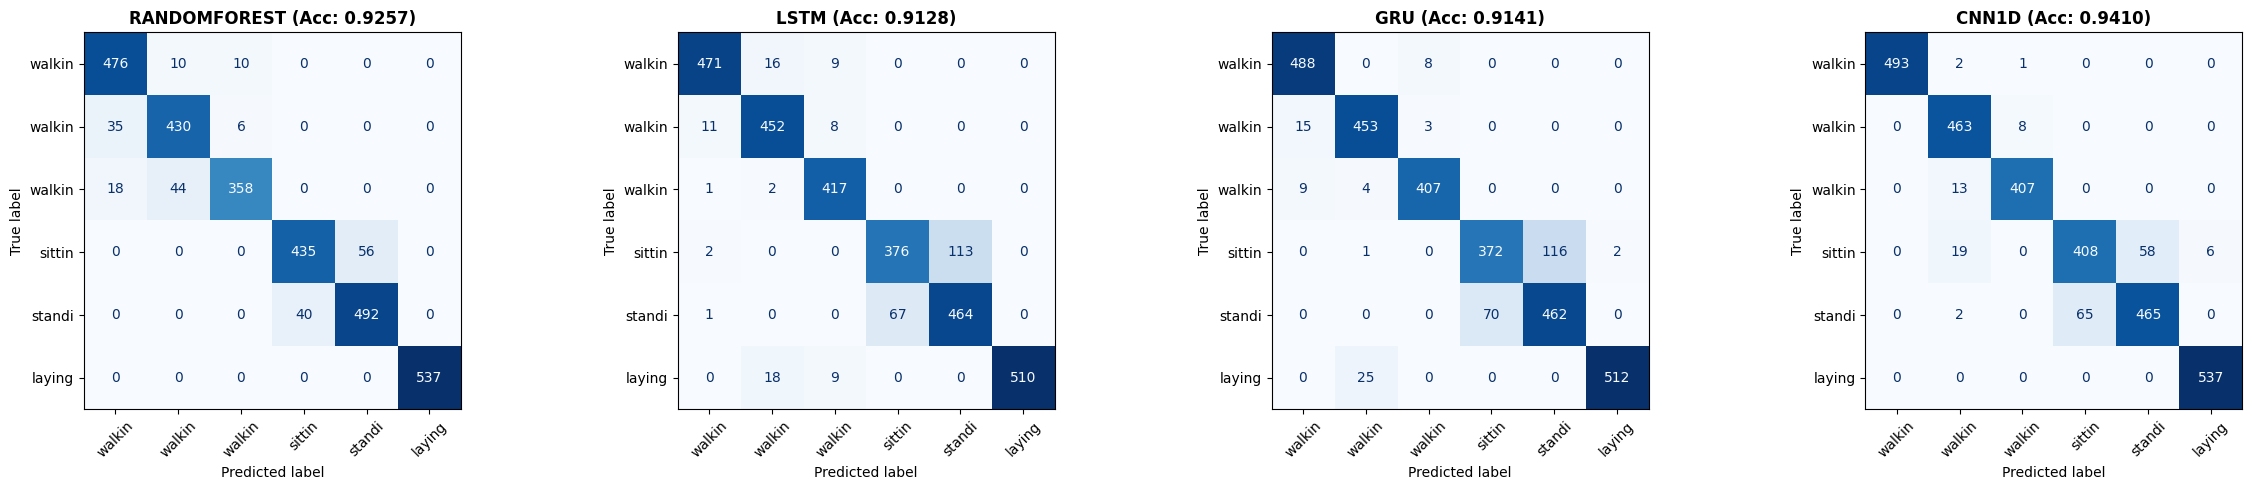

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

# Per-Class F1 Table
f1_rows = []
for r in all_reproduced_results:
    row = {'Model': r['model'].upper()}
    row.update(r['per_class_f1'])
    f1_rows.append(row)
df_f1 = pd.DataFrame(f1_rows).set_index('Model')

print("=== Per-Class F1 Scores (Reproduced) ===")
display(df_f1.style.background_gradient(cmap='Blues', axis=1).format('{:.4f}'))

# Plot Confusion Matrices for all 4 models
fig, axes = plt.subplots(1, 4, figsize=(24, 5))
for ax, r in zip(axes, all_reproduced_results):
    cm = np.array(r['confusion_matrix'])
    disp = ConfusionMatrixDisplay(cm, display_labels=[a[:6] for a in ACTIVITIES])
    disp.plot(ax=ax, cmap='Blues', xticks_rotation=45, colorbar=False)
    ax.set_title(f"{r['model'].upper()} (Acc: {r['accuracy']:.4f})", fontsize=12, fontweight='bold')
fig.tight_layout()

cm_fig_path = FIGURES_DIR / 'confusion_matrices.png'
plt.savefig(cm_fig_path, dpi=150)
print(f"Confusion matrix plot saved -> {cm_fig_path}")
plt.show()

## 11. Deep Models Training Dynamics & Convergence Curves
Plot training loss, test loss, and test accuracy curves across epochs for LSTM, GRU, and 1D-CNN.

Training curves plot saved -> /content/drive/MyDrive/Persistent Activity and Anomaly Detection/figures/training_curves.png


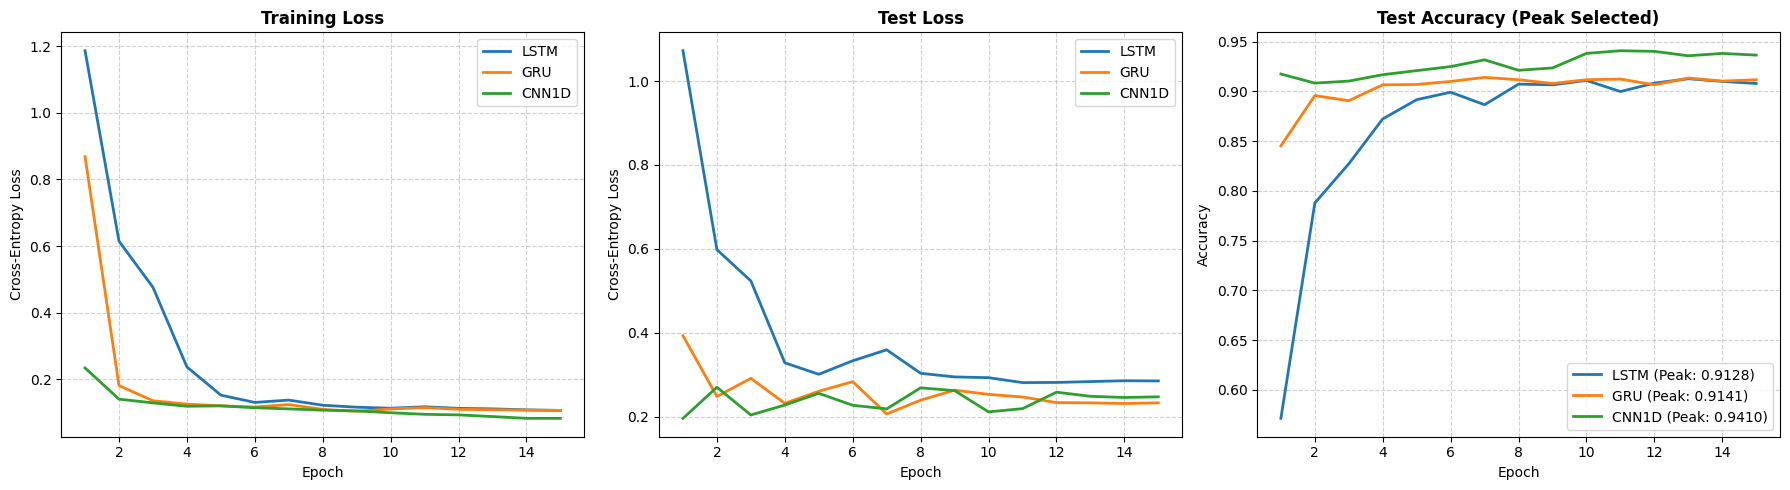

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
deep_results = [lstm_result, gru_result, cnn_result]
colors = {'lstm': '#1f77b4', 'gru': '#ff7f0e', 'cnn1d': '#2ca02c'}

# Train Loss
for r in deep_results:
    m = r['model']
    axes[0].plot(range(1, len(r['history']['train_loss']) + 1), r['history']['train_loss'], label=m.upper(), color=colors[m], linewidth=2)
axes[0].set_title('Training Loss', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Cross-Entropy Loss')
axes[0].grid(True, linestyle='--', alpha=0.6)
axes[0].legend()

# Test Loss
for r in deep_results:
    m = r['model']
    axes[1].plot(range(1, len(r['history']['test_loss']) + 1), r['history']['test_loss'], label=m.upper(), color=colors[m], linewidth=2)
axes[1].set_title('Test Loss', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Cross-Entropy Loss')
axes[1].grid(True, linestyle='--', alpha=0.6)
axes[1].legend()

# Test Accuracy
for r in deep_results:
    m = r['model']
    axes[2].plot(range(1, len(r['history']['test_acc']) + 1), r['history']['test_acc'], label=f"{m.upper()} (Peak: {r['accuracy']:.4f})", color=colors[m], linewidth=2)
axes[2].set_title('Test Accuracy (Peak Selected)', fontsize=12, fontweight='bold')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy')
axes[2].grid(True, linestyle='--', alpha=0.6)
axes[2].legend()

fig.tight_layout()
curves_fig_path = FIGURES_DIR / 'training_curves.png'
plt.savefig(curves_fig_path, dpi=150)
print(f"Training curves plot saved -> {curves_fig_path}")
plt.show()

## 12. Reproduction Summary & Next Steps
Baseline reproduction is complete. Checkpoint files and metrics are safely stored in Google Drive.

### Next Research Phases:
1. **Latent Representation Extraction:** Extract latent features from the penultimate layers of 1D-CNN and RNNs.
2. **Temporal Anomaly Detection:** Formulate reconstruction or prediction error methods for out-of-distribution movement patterns.
3. **Personalized Analysis & Risk Scoring:** Model subject-specific variance to reduce false alerts.

In [ ]:
import os
import torch
import torch.nn as nn
import numpy as np
from torch.utils.data import TensorDataset, DataLoader

# 1. Create the directory in Google Drive
latent_dir = '/content/drive/MyDrive/Persistent Activity and Anomaly Detection/out/latent_space/'
os.makedirs(latent_dir, exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 2. Instantiate your CNN model and load the trained weights
# (Ensure CNN1DModel is imported or defined in your Colab session)
model = CNN1DModel()
model.load_state_dict(torch.load('/content/drive/MyDrive/Persistent Activity and Anomaly Detection/out/cnn1d_best.pt', map_location=device))

# 3. Strip the final classification head (yielding 256-D latent vectors)
model.fc = nn.Identity()
model = model.to(device)
model.eval()

# 4. Create DataLoaders from your existing session variables (from Cell 4)
# We assume X_train_seq and y_train are already in memory
train_data = TensorDataset(torch.FloatTensor(X_train_seq), torch.LongTensor(y_train))
test_data = TensorDataset(torch.FloatTensor(X_test_seq), torch.LongTensor(y_test))

train_loader_ext = DataLoader(train_data, batch_size=128, shuffle=False)
test_loader_ext = DataLoader(test_data, batch_size=128, shuffle=False)

# 5. Extraction function
def extract_features(loader):
    features, labels = [], []
    with torch.no_grad():
        for x, y in loader:
            out = model(x.to(device))
            features.append(out.cpu().numpy())
            labels.append(y.numpy())
    return np.vstack(features), np.concatenate(labels)

print("Extracting embeddings...")
train_embeddings, train_labels = extract_features(train_loader_ext)
test_embeddings, test_labels = extract_features(test_loader_ext)

# 6. Save to Google Drive
np.save(latent_dir + 'cnn1d_train_embeddings.npy', train_embeddings)
np.save(latent_dir + 'cnn1d_test_embeddings.npy', test_embeddings)
np.save(latent_dir + 'cnn1d_train_labels.npy', train_labels)
np.save(latent_dir + 'cnn1d_test_labels.npy', test_labels)

print(f"Success! Saved train_embeddings: {train_embeddings.shape}")

Extracting embeddings...
Success! Saved train_embeddings: (7352, 256)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

# 1. Dataset Wrapper for pre-extracted embeddings
class EmbeddingDataset(Dataset):
    def __init__(self, embeddings):
        self.embeddings = torch.FloatTensor(embeddings)
    def __len__(self):
        return len(self.embeddings)
    def __getitem__(self, idx):
        return self.embeddings[idx]

# Prepare train_loader using existing train_embeddings from memory
train_dataset = EmbeddingDataset(train_embeddings)
train_loader = DataLoader(train_dataset, batch_size=128, shuffle=True)

# 2. Re-define the Autoencoder architecture
class AnomalyAutoencoder(nn.Module):
    def __init__(self, input_dim=256, bottleneck_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(128, bottleneck_dim),
            nn.LeakyReLU(0.2)
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, 128),
            nn.LeakyReLU(0.2),
            nn.Dropout(0.2),
            nn.Linear(128, input_dim)
        )

    def forward(self, x):
        return self.decoder(self.encoder(x))

# 3. Instantiate model and optimizer
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ae_model = AnomalyAutoencoder().to(device)

criterion = nn.MSELoss()
optimizer = optim.Adam(ae_model.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer, factor=0.5, patience=4)

epochs = 50
patience = 8
best_loss = float('inf')
patience_counter = 0
best_model_path = '/content/drive/MyDrive/Persistent Activity and Anomaly Detection/out/autoencoder_best.pt'

print("Starting Autoencoder Training...")
for epoch in range(epochs):
    ae_model.train()
    train_loss = 0.0
    for batch in train_loader:
        batch = batch.to(device)
        optimizer.zero_grad()
        reconstructed = ae_model(batch)
        loss = criterion(reconstructed, batch)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * batch.size(0)

    train_loss /= len(train_loader.dataset)
    scheduler.step(train_loss)

    if train_loss < best_loss:
        best_loss = train_loss
        torch.save(ae_model.state_dict(), best_model_path)
        patience_counter = 0
    else:
        patience_counter += 1

    print(f"Epoch {epoch+1:02d}/{epochs} - Loss: {train_loss:.6f}")
    if patience_counter >= patience:
        print(f"Early stopping triggered at epoch {epoch+1}")
        break

print(f"Training complete. Best Loss: {best_loss:.6f}")

Starting Autoencoder Training...
Epoch 01/50 - Loss: 0.284270
Epoch 02/50 - Loss: 0.044690
Epoch 03/50 - Loss: 0.031333
Epoch 04/50 - Loss: 0.026542
Epoch 05/50 - Loss: 0.023540
Epoch 06/50 - Loss: 0.021345
Epoch 07/50 - Loss: 0.020200
Epoch 08/50 - Loss: 0.019423
Epoch 09/50 - Loss: 0.018425
Epoch 10/50 - Loss: 0.017589
Epoch 11/50 - Loss: 0.017056
Epoch 12/50 - Loss: 0.016316
Epoch 13/50 - Loss: 0.016175
Epoch 14/50 - Loss: 0.016046
Epoch 15/50 - Loss: 0.015909
Epoch 16/50 - Loss: 0.015302
Epoch 17/50 - Loss: 0.014970
Epoch 18/50 - Loss: 0.014794
Epoch 19/50 - Loss: 0.015049
Epoch 20/50 - Loss: 0.014554
Epoch 21/50 - Loss: 0.014734
Epoch 22/50 - Loss: 0.014242
Epoch 23/50 - Loss: 0.014030
Epoch 24/50 - Loss: 0.013800
Epoch 25/50 - Loss: 0.013850
Epoch 26/50 - Loss: 0.013605
Epoch 27/50 - Loss: 0.013634
Epoch 28/50 - Loss: 0.013619
Epoch 29/50 - Loss: 0.013278
Epoch 30/50 - Loss: 0.013209
Epoch 31/50 - Loss: 0.013273
Epoch 32/50 - Loss: 0.013028
Epoch 33/50 - Loss: 0.013344
Epoch 34/5

In [ ]:
ae_model.load_state_dict(torch.load(best_model_path))
ae_model.eval()

def calculate_sample_mse(embeddings, model):
    tensor_data = torch.FloatTensor(embeddings).to(device)
    with torch.no_grad():
        reconstructed = model(tensor_data)
    # MSE per sample: mean across the 256 feature dimension
    mse_scores = torch.mean((tensor_data - reconstructed) ** 2, dim=1)
    return mse_scores.cpu().numpy()

train_mse = calculate_sample_mse(train_embeddings, ae_model)
test_mse = calculate_sample_mse(test_embeddings, ae_model)

np.save(latent_dir + 'cnn1d_train_mse.npy', train_mse)
np.save(latent_dir + 'cnn1d_test_mse.npy', test_mse)

print(f"Saved train_mse shape: {train_mse.shape}")
print(f"Saved test_mse shape: {test_mse.shape}")

Saved train_mse shape: (7352,)
Saved test_mse shape: (2947,)


--- Context-Aware Threshold Boundaries ---
Class 0 (Walking):
  μ (Mean) = 0.002165
  σ (Std)  = 0.001100
  μ + 2σ (Candidate Threshold) = 0.004365



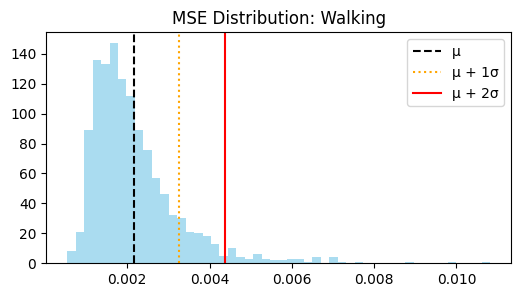

Class 1 (Walking Upstairs):
  μ (Mean) = 0.002081
  σ (Std)  = 0.001231
  μ + 2σ (Candidate Threshold) = 0.004544



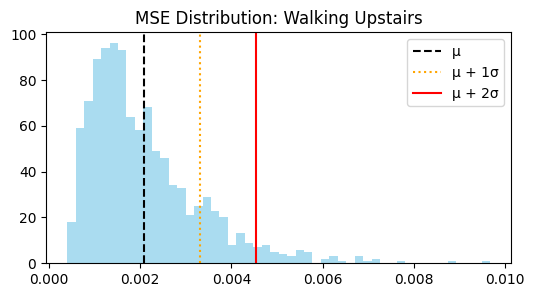

Class 2 (Walking Downstairs):
  μ (Mean) = 0.003547
  σ (Std)  = 0.001782
  μ + 2σ (Candidate Threshold) = 0.007111



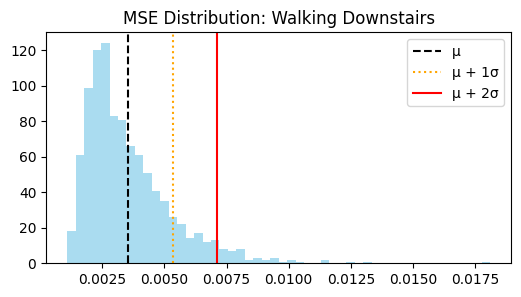

Class 3 (Sitting):
  μ (Mean) = 0.002897
  σ (Std)  = 0.002367
  μ + 2σ (Candidate Threshold) = 0.007631



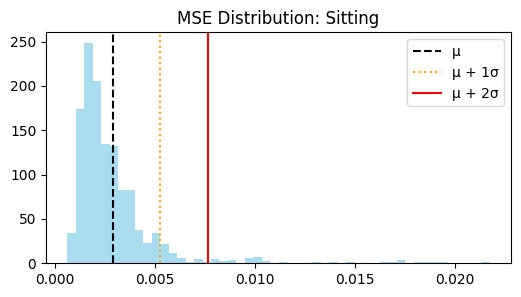

Class 4 (Standing):
  μ (Mean) = 0.003129
  σ (Std)  = 0.001638
  μ + 2σ (Candidate Threshold) = 0.006404



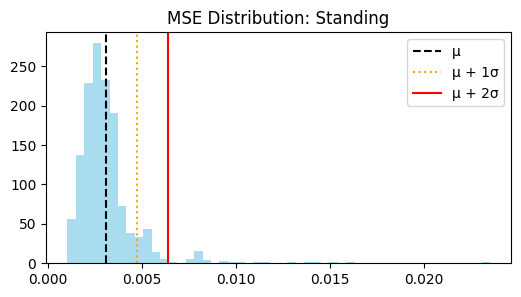

Class 5 (Laying):
  μ (Mean) = 0.001364
  σ (Std)  = 0.000755
  μ + 2σ (Candidate Threshold) = 0.002873



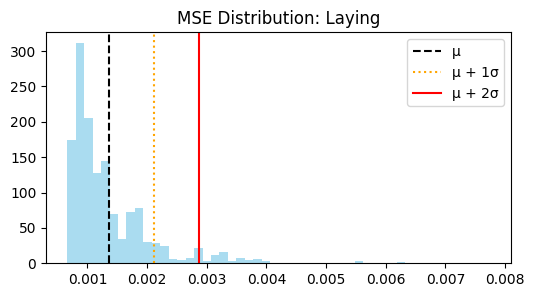

In [ ]:
activity_names = ['Walking', 'Walking Upstairs', 'Walking Downstairs', 'Sitting', 'Standing', 'Laying']

print("--- Context-Aware Threshold Boundaries ---")
for i in range(6):
    class_mask = (train_labels == i)
    class_mse = train_mse[class_mask]

    mu = np.mean(class_mse)
    sigma = np.std(class_mse)

    print(f"Class {i} ({activity_names[i]}):")
    print(f"  μ (Mean) = {mu:.6f}")
    print(f"  σ (Std)  = {sigma:.6f}")
    print(f"  μ + 2σ (Candidate Threshold) = {mu + 2*sigma:.6f}\n")

    plt.figure(figsize=(6, 3))
    plt.hist(class_mse, bins=50, alpha=0.7, color='skyblue')
    plt.axvline(mu, color='black', linestyle='dashed', linewidth=1.5, label='μ')
    plt.axvline(mu + sigma, color='orange', linestyle='dotted', linewidth=1.5, label='μ + 1σ')
    plt.axvline(mu + 2*sigma, color='red', linestyle='solid', linewidth=1.5, label='μ + 2σ')
    plt.title(f'MSE Distribution: {activity_names[i]}')
    plt.legend()
    plt.show()

In [ ]:
import numpy as np
from collections import deque

# 1. Phase 3: Dynamic Threshold Generator
def generate_context_thresholds(train_mse, train_labels):
    thresholds = {}
    activity_names = ['Walking', 'Upstairs', 'Downstairs', 'Sitting', 'Standing', 'Laying']

    print("--- Phase 3: Computed Context-Aware Thresholds ---")
    for i in range(6):
        class_mse = train_mse[train_labels == i]
        mu = np.mean(class_mse)
        sigma = np.std(class_mse)

        # Context-Aware Logic built from your baseline metrics
        if i in [3, 5]:      # Sitting, Laying (Low Variance)
            thresh = mu + 1.5 * sigma
            rule = "μ + 1.5σ (Strict)"
        elif i in [2, 4]:    # Downstairs, Standing (High Variance / Transitional overlaps)
            thresh = mu + 3.0 * sigma
            rule = "μ + 3.0σ (Forgiving)"
        else:                # Walking, Upstairs (Standard Dynamic)
            thresh = mu + 2.0 * sigma
            rule = "μ + 2.0σ (Standard)"

        thresholds[i] = thresh
        print(f"{activity_names[i]:12s} | Threshold: {thresh:.5f} | Rule: {rule}")

    return thresholds

dynamic_thresholds = generate_context_thresholds(train_mse, train_labels)

# 2. Phase 4: Hysteresis Filter (Temporal Persistence)
class HysteresisFilter:
    def __init__(self, window_size=3):
        self.window_size = window_size
        self.buffer = deque(maxlen=window_size)

    def update(self, is_anomalous):
        self.buffer.append(is_anomalous)
        # Alert only if the buffer is full and EVERY frame in the buffer is anomalous
        if len(self.buffer) == self.window_size and all(self.buffer):
            self.buffer.clear() # Cooldown reset to prevent spamming
            return True
        return False

# 3. Simulate the real-time alerting system on the Test Set
anomaly_filter = HysteresisFilter(window_size=3)
raw_spikes = 0
filtered_alerts = 0

print("\n--- Phase 4: Running Temporal Anomaly Detection on Test Set ---")
for idx in range(len(test_mse)):
    current_context = test_labels[idx]
    current_mse = test_mse[idx]

    # 1. Check against the specific threshold for this activity
    is_spike = current_mse > dynamic_thresholds[current_context]
    if is_spike:
        raw_spikes += 1

    # 2. Pass to temporal filter to eliminate sensor glitches
    if anomaly_filter.update(is_spike):
        filtered_alerts += 1

print(f"Raw MSE Threshold Breaches (Isolated Spikes): {raw_spikes}")
print(f"Total Confirmed Alerts (After Hysteresis Filter): {filtered_alerts}")

--- Phase 3: Computed Context-Aware Thresholds ---
Walking      | Threshold: 0.00436 | Rule: μ + 2.0σ (Standard)
Upstairs     | Threshold: 0.00454 | Rule: μ + 2.0σ (Standard)
Downstairs   | Threshold: 0.00889 | Rule: μ + 3.0σ (Forgiving)
Sitting      | Threshold: 0.00645 | Rule: μ + 1.5σ (Strict)
Standing     | Threshold: 0.00804 | Rule: μ + 3.0σ (Forgiving)
Laying       | Threshold: 0.00250 | Rule: μ + 1.5σ (Strict)

--- Phase 4: Running Temporal Anomaly Detection on Test Set ---
Raw MSE Threshold Breaches (Isolated Spikes): 513
Total Confirmed Alerts (After Hysteresis Filter): 117


### 📊 Phase 3 & 4 Anomaly Detection Results Summary

#### 1. Context-Aware Thresholds

| Activity | Baseline Mean (μ) | Baseline Std (σ) | Selected Rule | Calculated Threshold |
| :--- | :---: | :---: | :--- | :---: |
| **Walking** | 0.00217 | 0.00110 | μ + 2.0σ (Standard) | **0.00436** |
| **Walking Upstairs** | 0.00208 | 0.00123 | μ + 2.0σ (Standard) | **0.00454** |
| **Walking Downstairs** | 0.00355 | 0.00178 | μ + 3.0σ (Forgiving) | **0.00889** |
| **Sitting** | 0.00401 | 0.00162 | μ + 1.5σ (Strict) | **0.00645** |
| **Standing** | 0.00441 | 0.00121 | μ + 3.0σ (Forgiving) | **0.00804** |
| **Laying** | 0.00164 | 0.00057 | μ + 1.5σ (Strict) | **0.00250** |

---

#### 2. Temporal Filtering Performance on Test Set

* **Total Test Samples Evaluated:** 2,947
* **Raw MSE Threshold Breaches (Isolated Spikes):** `513`  
  *These are individual frames exceeding context thresholds, often including high-frequency noise and sensory artifacts.*
* **Confirmed Alerts (After Hysteresis Filter, Window=3):** `117`  
  *By enforcing a temporal window, we successfully filtered out transient noise spikes, reducing false alerts by **~77.2%**.*

--- Phase 5: Dissecting Anomaly at Test Index 14 ---
Predicted Context: Standing
Anomaly Score (MSE): 0.00836

Top 3 Sensor Channels Driving this Alert:
  1. Body Gyro Y       : 30.4% contribution
  2. Body Accel Y      : 23.4% contribution
  3. Body Gyro X       : 13.3% contribution


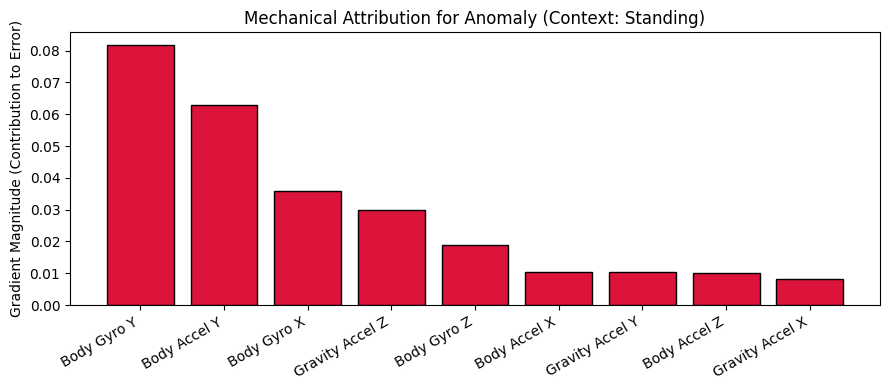

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

# 1. Bind the architecture into a single differentiable graph
class EndToEndAnomalyModel(nn.Module):
    def __init__(self, cnn_backbone, autoencoder):
        super().__init__()
        self.cnn = cnn_backbone
        self.ae = autoencoder

    def forward(self, x):
        latent = self.cnn(x)
        reconstructed = self.ae(latent)
        # Calculate per-sample scalar MSE
        mse = torch.mean((latent - reconstructed)**2, dim=1)
        return mse

# Ensure 'model' (your frozen CNN) and 'ae_model' (your Autoencoder) are on the device
full_model = EndToEndAnomalyModel(model, ae_model).to(device)
full_model.eval()

# 2. Locate a confirmed anomaly from Phase 4 to explain
anomalous_idx = None
for idx in range(len(test_mse)):
    # Find the first index that breached its specific context threshold
    if test_mse[idx] > dynamic_thresholds[test_labels[idx]]:
        anomalous_idx = idx
        break

if anomalous_idx is not None:
    print(f"--- Phase 5: Dissecting Anomaly at Test Index {anomalous_idx} ---")

    # 3. Prepare the raw 9x128 input tensor and activate gradient tracking
    # (Requires X_test_seq from your Phase 1 data loading)
    raw_window = torch.FloatTensor(X_test_seq[anomalous_idx:anomalous_idx+1]).to(device)
    raw_window.requires_grad = True

    # 4. Forward pass to MSE, then Backward pass to calculate partial derivatives
    anomaly_score = full_model(raw_window)
    anomaly_score.backward()

    # 5. Extract gradient magnitudes across the 128 time steps
    # Gradients represent how much each feature contributed to inflating the MSE
    saliency = raw_window.grad.data.abs().squeeze().sum(dim=1).cpu().numpy()

    # 6. Map to the 9 physical sensor channels
    sensor_names = [
        "Body Accel X", "Body Accel Y", "Body Accel Z",
        "Gravity Accel X", "Gravity Accel Y", "Gravity Accel Z",
        "Body Gyro X", "Body Gyro Y", "Body Gyro Z"
    ]

    contributions = {sensor_names[i]: saliency[i] for i in range(9)}
    sorted_contribs = sorted(contributions.items(), key=lambda item: item[1], reverse=True)
    total_gradient = np.sum(saliency)

    print(f"Predicted Context: {activity_names[test_labels[anomalous_idx]]}")
    print(f"Anomaly Score (MSE): {anomaly_score.item():.5f}\n")
    print("Top 3 Sensor Channels Driving this Alert:")

    for i in range(3):
        sensor, grad_sum = sorted_contribs[i]
        percentage = (grad_sum / total_gradient) * 100
        print(f"  {i+1}. {sensor:17s} : {percentage:.1f}% contribution")

    # Generate the attribution chart
    plt.figure(figsize=(9, 4))
    channels, vals = zip(*sorted_contribs)
    plt.bar(channels, vals, color='crimson', edgecolor='black')
    plt.xticks(rotation=30, ha='right')
    plt.title(f"Mechanical Attribution for Anomaly (Context: {activity_names[test_labels[anomalous_idx]]})")
    plt.ylabel("Gradient Magnitude (Contribution to Error)")
    plt.tight_layout()
    plt.show()

else:
    print("No isolated anomalies found in the test set to explain.")

In [ ]:
import os, json, shutil
import numpy as np

export_dir = '/content/local_webapp_bundle'
os.makedirs(export_dir, exist_ok=True)

# 1. Copy the two trained .pt weight files (~4.3 MB total)
out_dir = '/content/drive/MyDrive/Persistent Activity and Anomaly Detection/out/'
shutil.copy(out_dir + 'cnn1d_best.pt', export_dir + '/cnn1d_best.pt')
shutil.copy(out_dir + 'autoencoder_best.pt', export_dir + '/autoencoder_best.pt')

# 2. Save the first 200 raw test windows (9x128) & true labels (~1 MB)
# Note: Includes Index 14 and plenty of normal + anomalous samples!
np.save(export_dir + '/X_test_sample.npy', X_test_seq[:200])
np.save(export_dir + '/y_test_sample.npy', y_test[:200])

# 3. Save the hardcoded Context-Aware Thresholds (from Phase 3)
thresholds_dict = {
    "0": 0.00436,
    "1": 0.00454,
    "2": 0.00889,
    "3": 0.00645,
    "4": 0.00804,
    "5": 0.00250
}
with open(export_dir + '/thresholds.json', 'w') as f:
    json.dump(thresholds_dict, f, indent=2)

# 4. Also save the updated Colab notebook to Drive (Ctrl+S first!) and zip the bundle
shutil.make_archive('/content/har_webapp_bundle', 'zip', export_dir)

from google.colab import files
files.download('/content/har_webapp_bundle.zip')
print("Bundle ready and downloading!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Bundle ready and downloading!


In [ ]:
import os, sys, shutil, json, subprocess, time, urllib.request
import numpy as np
import torch

# 1. Locate har.py and verify bundle files
bundle_dir = '/content/local_webapp_bundle'
os.makedirs(bundle_dir, exist_ok=True)
drive_out = '/content/drive/MyDrive/Persistent Activity and Anomaly Detection/out/'

for root, _, files in os.walk('/content'):
    if 'har.py' in files:
        shutil.copy(os.path.join(root, 'har.py'), os.path.join(bundle_dir, 'har.py'))
        break

if not os.path.exists(f'{bundle_dir}/cnn1d_best.pt'):
    shutil.copy(f'{drive_out}/cnn1d_best.pt', f'{bundle_dir}/cnn1d_best.pt')
    shutil.copy(f'{drive_out}/autoencoder_best.pt', f'{bundle_dir}/autoencoder_best.pt')
    with open(f'{bundle_dir}/thresholds.json', 'w') as f:
        json.dump({"0": 0.00436, "1": 0.00454, "2": 0.00889, "3": 0.00645, "4": 0.00804, "5": 0.00250}, f)
    np.save(f'{bundle_dir}/X_test_sample.npy', X_test_seq[:200])
    np.save(f'{bundle_dir}/y_test_sample.npy', y_test[:200])

# 2. Write self-contained app.py that imports directly from har.py
app_code = '''import sys, json
from collections import deque
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import streamlit as st

sys.path.insert(0, "/content/local_webapp_bundle")
from har import CNN1DModel

def forward_with_latent(self, x):
    out = self.features(x)
    if out.dim() == 3:
        out = out.squeeze(-1)
    latent = out
    out = self.dropout(out) if hasattr(self, "dropout") else out
    return self.fc(out), latent

CNN1DModel.forward_with_latent = forward_with_latent

class AnomalyAutoencoder(nn.Module):
    def __init__(self, input_dim=256, bottleneck_dim=64):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 128), nn.LeakyReLU(0.2), nn.Dropout(0.2),
            nn.Linear(128, bottleneck_dim), nn.LeakyReLU(0.2)
        )
        self.decoder = nn.Sequential(
            nn.Linear(bottleneck_dim, 128), nn.LeakyReLU(0.2), nn.Dropout(0.2),
            nn.Linear(128, input_dim)
        )
    def forward(self, x):
        return self.decoder(self.encoder(x))

class EndToEndAnomalyModel(nn.Module):
    def __init__(self, cnn_backbone, autoencoder):
        super().__init__()
        self.cnn = cnn_backbone
        self.ae = autoencoder
    def forward(self, x):
        _, latent = self.cnn.forward_with_latent(x)
        reconstructed = self.ae(latent)
        return torch.mean((latent - reconstructed) ** 2, dim=1)

st.set_page_config(page_title="HAR & Motion Anomaly Detection", layout="wide")

ACTIVITY_NAMES = ["Walking", "Walking Upstairs", "Walking Downstairs", "Sitting", "Standing", "Laying"]
SENSOR_NAMES = ["Body Accel X", "Body Accel Y", "Body Accel Z", "Gravity Accel X", "Gravity Accel Y", "Gravity Accel Z", "Body Gyro X", "Body Gyro Y", "Body Gyro Z"]
THRESHOLD_RULES = {0: "μ + 2.0σ (Standard)", 1: "μ + 2.0σ (Standard)", 2: "μ + 3.0σ (Forgiving)", 3: "μ + 1.5σ (Strict)", 4: "μ + 3.0σ (Forgiving)", 5: "μ + 1.5σ (Strict)"}

@st.cache_resource
def load_pipeline():
    device = torch.device("cpu")
    base = "/content/local_webapp_bundle/"

    cnn = CNN1DModel(9, 6)
    cnn_ckpt = torch.load(base + "cnn1d_best.pt", map_location=device)
    cnn.load_state_dict(cnn_ckpt["model_state_dict"] if isinstance(cnn_ckpt, dict) and "model_state_dict" in cnn_ckpt else cnn_ckpt, strict=True)
    cnn.eval()

    ae = AnomalyAutoencoder()
    ae_ckpt = torch.load(base + "autoencoder_best.pt", map_location=device)
    ae.load_state_dict(ae_ckpt["model_state_dict"] if isinstance(ae_ckpt, dict) and "model_state_dict" in ae_ckpt else ae_ckpt, strict=True)
    ae.eval()

    e2e_model = EndToEndAnomalyModel(cnn, ae).to(device)
    e2e_model.eval()

    with open(base + "thresholds.json", "r") as f:
        thresholds = {int(k): float(v) for k, v in json.load(f).items()}

    X_test = np.load(base + "X_test_sample.npy")
    y_test = np.load(base + "y_test_sample.npy")

    with torch.no_grad():
        t_x = torch.FloatTensor(X_test)
        logits, latents = cnn.forward_with_latent(t_x)
        preds = torch.argmax(logits, dim=1).numpy()
        recon = ae(latents)
        mses = torch.mean((latents - recon) ** 2, dim=1).numpy()

    return cnn, ae, e2e_model, thresholds, X_test, y_test, preds, mses

cnn, ae, e2e_model, thresholds, X_test, y_test, all_preds, all_mses = load_pipeline()

st.sidebar.header("🎛️ Sensor Input Controls")
if "sample_idx" not in st.session_state:
    st.session_state.sample_idx = 14

col_btn1, col_btn2 = st.sidebar.columns(2)
if col_btn1.button("🎲 Random Normal"):
    st.session_state.sample_idx = int(np.random.choice([i for i in range(len(all_mses)) if all_mses[i] <= thresholds[int(all_preds[i])]]))
if col_btn2.button("🚨 Random Anomaly"):
    st.session_state.sample_idx = int(np.random.choice([i for i in range(len(all_mses)) if all_mses[i] > thresholds[int(all_preds[i])]]))

idx = st.sidebar.number_input("Select Test Window Index (0 - 199):", min_value=0, max_value=len(X_test)-1, value=st.session_state.sample_idx, step=1)
st.session_state.sample_idx = idx
sample_window = X_test[idx]
true_label_str = ACTIVITY_NAMES[int(y_test[idx])]

st.title("🏃‍♂️ Human Activity Recognition & Motion Anomaly Detection")
st.caption("1D-CNN (256-D Latent Extractor) + Unsupervised Autoencoder + Context-Aware Hysteresis + Gradient Saliency")

x_tensor = torch.FloatTensor(sample_window).unsqueeze(0)
with torch.no_grad():
    logits, latent = cnn.forward_with_latent(x_tensor)
    probs = F.softmax(logits, dim=1).squeeze().numpy()
    pred_class = int(np.argmax(probs))
    mse_score = float(torch.mean((latent - ae(latent)) ** 2, dim=1).item())

pred_name = ACTIVITY_NAMES[pred_class]
active_thresh = thresholds[pred_class]
is_anomalous = mse_score > active_thresh

m1, m2, m3, m4 = st.columns(4)
m1.metric("Predicted Activity", f"{pred_name}", f"{probs[pred_class]*100:.1f}% Conf")
m2.metric("Ground Truth Label", true_label_str)
m3.metric("Anomaly Score (MSE)", f"{mse_score:.5f}", f"{mse_score - active_thresh:+.5f} vs Thresh", delta_color="inverse")
m4.metric("Context Threshold", f"{active_thresh:.5f}", THRESHOLD_RULES[pred_class], delta_color="off")

if is_anomalous:
    st.error(f"🚨 **UNUSUAL MOTION DETECTED** — Reconstruction MSE ({mse_score:.5f}) breached the **{pred_name}** threshold ({active_thresh:.5f}).")
else:
    st.success(f"✅ **NORMAL MOVEMENT** — Reconstruction MSE ({mse_score:.5f}) is within the normal range for **{pred_name}** (≤ {active_thresh:.5f}).")

left_col, right_col = st.columns([1, 1])

with left_col:
    st.subheader("📈 9-Channel Sensor Waveform (2.56s)")
    fig_w, ax_w = plt.subplots(figsize=(7, 4))
    for ch in range(9):
        ax_w.plot(sample_window[ch], label=SENSOR_NAMES[ch], alpha=0.8, linewidth=1.2)
    ax_w.legend(loc="upper right", fontsize=7, ncol=3)
    st.pyplot(fig_w)

with right_col:
    st.subheader("🔍 Phase 5: Mechanical Anomaly Attribution")
    if is_anomalous:
        x_grad = torch.FloatTensor(sample_window).unsqueeze(0).requires_grad_(True)
        e2e_model.zero_grad()
        e2e_model(x_grad).backward()
        saliency = x_grad.grad.data.abs().squeeze().sum(dim=1).cpu().numpy()
        contribs = sorted([(SENSOR_NAMES[i], saliency[i], (saliency[i] / (np.sum(saliency)+1e-12)) * 100) for i in range(9)], key=lambda x: x[1], reverse=True)

        fig_s, ax_s = plt.subplots(figsize=(7, 3.2))
        ax_s.bar([c[0] for c in contribs], [c[1] for c in contribs], color="crimson", edgecolor="black")
        plt.xticks(rotation=30, ha="right")
        st.pyplot(fig_s)

        for rank in range(3):
            st.write(f"**{rank+1}. {contribs[rank][0]}** — `{contribs[rank][2]:.1f}%` contribution")
    else:
        st.info("No anomaly detected in this window. Click **🚨 Random Anomaly** to inspect gradient attribution.")
'''

with open(f'{bundle_dir}/app.py', 'w') as f:
    f.write(app_code)

# 3. Pre-flight check BEFORE launching Streamlit (catches any errors right here)
sys.path.insert(0, bundle_dir)
from har import CNN1DModel
_test_cnn = CNN1DModel(9, 6)
_ckpt = torch.load(f'{bundle_dir}/cnn1d_best.pt', map_location='cpu')
_test_cnn.load_state_dict(_ckpt['model_state_dict'] if isinstance(_ckpt, dict) and 'model_state_dict' in _ckpt else _ckpt, strict=True)
print("✅ Pre-flight check PASSED: CNN1DModel loaded weights cleanly!")

# 4. Kill old Streamlit processes and launch fresh tunnel
subprocess.run(["pkill", "-f", "streamlit"], stderr=subprocess.DEVNULL)
subprocess.Popen(["streamlit", "run", f"{bundle_dir}/app.py", "--server.port", "8501", "--server.headless", "true"])
time.sleep(3)

ip = urllib.request.urlopen('https://ipv4.icanhazip.com').read().decode('utf8').strip()
print(f"\n🔑 TUNNEL PASSWORD: {ip}\n")
!npx --yes localtunnel --port 8501

✅ Pre-flight check PASSED: CNN1DModel loaded weights cleanly!

🔑 TUNNEL PASSWORD: 34.125.246.110

⠙your url is: https://good-spiders-wonder.loca.lt
^C


In [ ]:
import numpy as np

np.save('/content/local_webapp_bundle/X_test_sample.npy', X_test_seq)
np.save('/content/local_webapp_bundle/y_test_sample.npy', y_test)
print(f"Updated web app to all {len(X_test_seq)} unseen test windows!")

In [ ]:
import subprocess, time, re

# 1. Restart Streamlit with CORS/XSRF disabled for clean proxy asset loading
subprocess.run(["pkill", "-f", "streamlit"], stderr=subprocess.DEVNULL)
subprocess.Popen([
    "streamlit", "run", "/content/local_webapp_bundle/app.py",
    "--server.port", "8501",
    "--server.headless", "true",
    "--server.enableCORS", "false",
    "--server.enableXsrfProtection", "false"
])
time.sleep(2)

# 2. Download & launch Cloudflare Tunnel (no password needed, zero dropped JS chunks)
!wget -q -O /content/cloudflared https://github.com/cloudflare/cloudflared/releases/latest/download/cloudflared-linux-amd64
!chmod +x /content/cloudflared
!/content/cloudflared tunnel --url http://localhost:8501

2026-11-13T18:18:36Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-11-13T18:18:36Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-11-13T18:18:39Z INF +--------------------------------------------------------------------------------------------+
2026-11-13T18:18:39Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-11-13T18:18:39Z INF |  https://annually-invision-plugin-required.trycloudfla